# clock/12.2 — GoalScope evaluation axes

Parses the saved `eval_goalscope` / `eval_residual_patchscope` runs under
`results/evaluation/goalscope/<model>/<mode>/<strategy>/<alpha>/<leaf>/` and answers four questions.
**No model is loaded** — this notebook is pure parsing (`faithfulness_io` + `records.jsonl`).

| § | question | design point |
|---|---|---|
| 1 | **Baseline** — does the head encoding beat the full residual (original patchscope)? | Coder-32B, `additive_norm`, α=0.1 |
| 2 | **Sparsity** — how does read-out quality scale with the number of heads? | Coder-32B, `additive_norm`, α=0.1, 50…300 heads |
| 3 | **Axes** — model size (14B vs 32B), code-finetuning, RL-finetuning | `replace` α=1.0 (and `additive_norm` where available) |
| 4 | **Anchor profile** — is the goal readable at `indent`, *before* the sub-task's first token? Does code/RL tuning change that? | per-anchor `hard_yes` |

**Two comparability rules applied throughout.**

1. *Matched corpus.* Runs differ in `n_specs` (256 vs 512). The 256-spec corpus is a strict **subset**
   of the 512-spec corpus (same seed), so whenever a comparison spans both, every number is
   recomputed from `records.jsonl` on the **intersection** of spec ids rather than read off
   `summary.json`. Cells state which they use.
2. *Metric.* `hard_yes` = fraction of anchors the grading oracle scored `YES` (read-out is
   genuinely relevant to the implementation span). `faithfulness` grades an NL description;
   `causality` grades a C++ re-implementation. They are **different rubrics** — compare a model to a
   model within a mode, never faithfulness to causality.


In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, json, logging
sys.path.append("../..")

from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rich.console import Console
from rich.table import Table
from rich.box import SIMPLE_HEAVY
from matplotlib.patches import Patch
import matplotlib.colors as mcolors

from scripts.evaluation import faithfulness_io as fio
from src.utils import env_utils

console = Console(highlight=False)
def rich_print(*a, **k): console.print(*a, **k)

RES = env_utils.DEFAULT_RESULTS_DIR
ROOT = fio.goalscope_root(RES)
ANCHORS = ["prev_end", "indent", "var", "eq", "first_impl"]
FIGDIR = Path(RES) / "goal_eval" / "axis"
FIGDIR.mkdir(parents=True, exist_ok=True)

# ── figure conventions: identical to notebooks/fig_n_table_generators/eval_goal.ipynb ──
# matte/muted tone per PROBING TOKEN POSITION (from clock/12.1); position is always the x-axis.
# solid bar = faithfulness, striped ("///") bar = causality.
plt.rcParams["figure.dpi"] = 120
ANCHOR_COLOR = {
    "prev_end": "#b5675f", "indent": "#6b6aa1", "var": "#d1a054",
    "eq": "#a7c48a", "first_impl": "#3f8079", "OVERALL": "#9a9a9a",
}
HATCH = "///"
NEUTRAL = "#9a9a9a"
print("runs root:", ROOT)
print("figures ->", FIGDIR)


runs root: /disk/u/arnab/Codes/Projects/goals/results/evaluation/goalscope
figures -> /disk/u/arnab/Codes/Projects/goals/results/goal_eval/axis


In [2]:
# ── index every run: config + summary, one row each ──────────────────────────
def run_index() -> pd.DataFrame:
    rows = []
    for cfg_path in sorted(ROOT.rglob("config.json")):
        d = cfg_path.parent
        c = json.loads(cfg_path.read_text())
        s = json.loads((d / "summary.json").read_text()) if (d / "summary.json").exists() else {}
        rows.append(dict(
            model=str(c.get("model", "?")).split("/")[-1],
            mode=fio.config_mode(c),
            strategy=c.get("strategy"),
            alpha=c.get("alpha"),
            heads_name=c.get("heads_name"),
            n_heads=c.get("n_heads"),
            goal_band=tuple(c["goal_band"]) if c.get("goal_band") else None,
            n_specs=c.get("n_specs"),
            seed=c.get("seed"),
            summary_hard_yes=(s.get("overall") or {}).get("hard_yes"),
            n_records=s.get("n_records"),
            dir=str(d),
        ))
    return pd.DataFrame(rows)


runs = run_index()
print(f"{len(runs)} runs | models: {sorted(runs.model.unique())}")
runs.groupby(["model", "mode", "strategy"]).size().to_frame("runs")


34 runs | models: ['Olmo-3.1-32B-Instruct', 'Olmo-3.1-32B-Instruct-SFT', 'Qwen2.5-32B-Instruct', 'Qwen2.5-Coder-14B-Instruct', 'Qwen2.5-Coder-32B-Instruct']


runs
model                      mode         strategy           
Olmo-3.1-32B-Instruct      causality    replace           1
                           faithfulness replace           1
Olmo-3.1-32B-Instruct-SFT  causality    replace           1
                           faithfulness replace           1
Qwen2.5-32B-Instruct       causality    replace           1
                           faithfulness replace           1
Qwen2.5-Coder-14B-Instruct causality    additive_norm     1
                                        replace           1
                           faithfulness additive_norm     1
                                        replace           1
Qwen2.5-Coder-32B-Instruct causality    additive          2
                                        additive_norm     7
                                        replace           1
                                        resid_norm        1
                           faithfulness additive          3
                                        additive_norm     7
                                        replace           2
                                        resid_norm        1

In [3]:
# ── records loader + matched-subset aggregation ──────────────────────────────
# Only 3 fields are kept (the raw oracle prompts/responses are ~180MB in total and unused here).
_REC_CACHE: dict[str, pd.DataFrame] = {}


def records(run_dir) -> pd.DataFrame:
    """(spec, anchor, hard) for one run, cached."""
    key = str(run_dir)
    if key not in _REC_CACHE:
        rows = []
        with open(Path(run_dir) / "records.jsonl") as fh:
            for line in fh:
                if not line.strip():
                    continue
                r = json.loads(line)
                rows.append((r["spec"], r["anchor"], r["hard"]))
        df = pd.DataFrame(rows, columns=["spec", "anchor", "hard"])
        df["hard_yes"] = (df.hard == "YES").astype(float)
        _REC_CACHE[key] = df
    return _REC_CACHE[key]


def spec_set(run_dir) -> set:
    return set(records(run_dir).spec.unique())


def matched_specs(run_dirs) -> set:
    """Intersection of spec ids across runs — the corpus every one of them actually covers."""
    sets = [spec_set(d) for d in run_dirs]
    return set.intersection(*sets) if sets else set()


def agg(run_dir, specs=None) -> dict:
    """overall + per-anchor hard_yes, optionally restricted to `specs`."""
    df = records(run_dir)
    if specs is not None:
        df = df[df.spec.isin(specs)]
    by = df.groupby("anchor").hard_yes.mean()
    out = dict(overall=float(df.hard_yes.mean()), n_records=len(df), n_specs=df.spec.nunique())
    out.update({a: float(by.get(a, np.nan)) for a in ANCHORS})
    return out


def compare(labelled_dirs: dict, match=True) -> pd.DataFrame:
    """One row per label. `match=True` restricts all rows to the shared spec ids."""
    specs = matched_specs(list(labelled_dirs.values())) if match else None
    rows = []
    for label, d in labelled_dirs.items():
        rows.append(dict(label=label, **agg(d, specs)))
    df = pd.DataFrame(rows).set_index("label")
    if match:
        print(f"matched corpus: {len(specs)} specs")
    return df


def show(df, title, cols=None, fmt="{:.3f}"):
    cols = cols or (["overall"] + ANCHORS)
    t = Table(title=title, box=SIMPLE_HEAVY)
    t.add_column("", style="bold")
    for c in cols:
        t.add_column(c, justify="right")
    for label, r in df.iterrows():
        t.add_row(str(label), *[fmt.format(r[c]) if isinstance(r[c], float) and not np.isnan(r[c])
                                else "—" for c in cols])
    rich_print(t)


def pick(model, mode, strategy, alpha=None, heads_name=None, n_specs=None, n_heads=None) -> str:
    """The single run dir matching these fields (raises unless exactly one matches)."""
    q = runs[(runs.model == model) & (runs["mode"] == mode) & (runs.strategy == strategy)]
    for col, val in [("alpha", alpha), ("heads_name", heads_name),
                     ("n_specs", n_specs), ("n_heads", n_heads)]:
        if val is not None:
            q = q[q[col] == val]
    assert len(q) == 1, f"want 1 run, got {len(q)}:\n{q[['model','mode','strategy','alpha','heads_name','n_heads','n_specs']]}"
    return q.iloc[0]["dir"]


def shade(color, t: float):
    """Blend `color` toward white; t=0 keeps it, t=1 is nearly white."""
    r, g, b = mcolors.to_rgb(color)
    return (r + (1 - r) * t, g + (1 - g) * t, b + (1 - b) * t)


def anchor_bars(ax, faith, causal, labels=None, ns=None, annotate=True, fs=7):
    """The eval_goal.ipynb chart: token positions on x, matte color per position,
    solid = faithfulness, striped = causality."""
    labels = list(labels if labels is not None else ANCHORS + ["OVERALL"])
    colors = [ANCHOR_COLOR.get(a, NEUTRAL) for a in labels]
    x, w = np.arange(len(labels)), 0.38
    b1 = ax.bar(x - w / 2, faith, w, color=colors, edgecolor="white", linewidth=0.6)
    b2 = ax.bar(x + w / 2, causal, w, color=colors, edgecolor="white", linewidth=0.6, hatch=HATCH)
    if annotate:
        for bars in (b1, b2):
            for r in bars:
                h = r.get_height()
                if h == h:  # not NaN
                    ax.annotate(f"{h:.2f}", (r.get_x() + r.get_width() / 2, h),
                                ha="center", va="bottom", fontsize=fs)
    if "OVERALL" in labels:
        ax.axvline(labels.index("OVERALL") - 0.5, color="grey", ls=":", lw=1)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{a}\n(n={n})" for a, n in zip(labels, ns)] if ns else labels, fontsize=8)
    ax.set_ylim(0, 1.10)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    return b1, b2


def metric_legend(ax, **kw):
    """Solid vs striped key, drawn in neutral grey so it never clashes with a position color."""
    opts = dict(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=8, frameon=False,
                borderaxespad=0.0, columnspacing=1.6, handlelength=1.8)
    opts.update(kw)
    ax.legend(handles=[Patch(facecolor=NEUTRAL, label="faithfulness"),
                       Patch(facecolor=NEUTRAL, hatch=HATCH, label="causality")], **opts)


def position_legend(ax, labels=None, **kw):
    labels = list(labels if labels is not None else ANCHORS)
    opts = dict(fontsize=7.5, frameon=False, ncol=1, loc="lower left")
    opts.update(kw)
    ax.legend(handles=[Patch(facecolor=ANCHOR_COLOR[a], label=a) for a in labels], **opts)


LAB = ANCHORS + ["OVERALL"]


def _row(df, key):
    """A compare()/axis-table row as [per-anchor..., overall], ordered like LAB."""
    r = df.loc[key]
    return [r[a] for a in ANCHORS] + [r["overall"]]


def paired_position_bars(ax, series: dict, mode: str, labels=None, annotate=True, fs=6.2):
    """Compared conditions side by side within ONE axes.

    x            = probing token position (matte colour per position, as in eval_goal.ipynb)
    fill pattern = metric: solid for faithfulness, striped for causality (constant per figure,
                   since each figure covers one metric)
    shade        = which condition (dark = first entry of `series`, lighter = later ones)
    """
    labels = list(labels if labels is not None else LAB)
    hatch = HATCH if mode == "causality" else None
    n = len(series)
    x, w = np.arange(len(labels)), 0.8 / n
    for j, (lbl, vals) in enumerate(series.items()):
        t = 0.0 if n == 1 else 0.58 * j / (n - 1)
        bars = ax.bar(x + (j - (n - 1) / 2) * w, vals, w,
                      color=[shade(ANCHOR_COLOR.get(a, NEUTRAL), t) for a in labels],
                      edgecolor="white", linewidth=0.6, hatch=hatch)
        if annotate:
            for r in bars:
                h = r.get_height()
                if h == h:
                    ax.annotate(f"{h:.2f}", (r.get_x() + r.get_width() / 2, h),
                                ha="center", va="bottom", fontsize=fs)
    if "OVERALL" in labels:
        ax.axvline(labels.index("OVERALL") - 0.5, color="grey", ls=":", lw=1)
    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8)
    ax.set_ylim(0, 1.12); ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)


def series_legend(ax, series_labels, mode, **kw):
    """Key for the compared conditions: neutral greys shaded like the bars, hatched per metric."""
    hatch = HATCH if mode == "causality" else None
    n = len(series_labels)
    handles = [Patch(facecolor=shade(NEUTRAL, 0.0 if n == 1 else 0.58 * j / (n - 1)),
                     hatch=hatch, edgecolor="white", label=l)
               for j, l in enumerate(series_labels)]
    opts = dict(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=min(n, 3), fontsize=8,
                frameon=False, borderaxespad=0.0, columnspacing=1.4, handlelength=1.8)
    opts.update(kw)
    ax.legend(handles=handles, **opts)


print("helpers ready")


helpers ready


## 1. Baseline — head encoding vs full residual (original patchscope)

Same model, same probe, same injection rule (norm-relative, α=0.1), same 512-spec corpus. The only
difference is **what** is transplanted: the selected goal heads' o_proj contribution
(`additive_norm`, 122 heads) versus the whole residual stream averaged over layers 25–55
(`resid_norm`, i.e. the original patchscope). If the head encoding wins, the goal signal is
*localised* rather than smeared across the residual.


matched corpus: 512 specs


      §1  head encoding vs full residual — Qwen2.5-Coder-32B, additive/resid_norm α=0.1      
                                                                                             
                                   overall   prev_end   indent     var      eq   first_impl  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  heads (122)  · faithfulness        0.674      0.331    0.577   0.491   0.986        0.986  
  residual L25-55 · faithfulness     0.240      0.003    0.058   0.054   0.613        0.471  
  heads (122)  · causality           0.800      0.586    0.838   0.687   0.912        0.979  
  residual L25-55 · causality        0.513      0.226    0.367   0.414   0.739        0.817

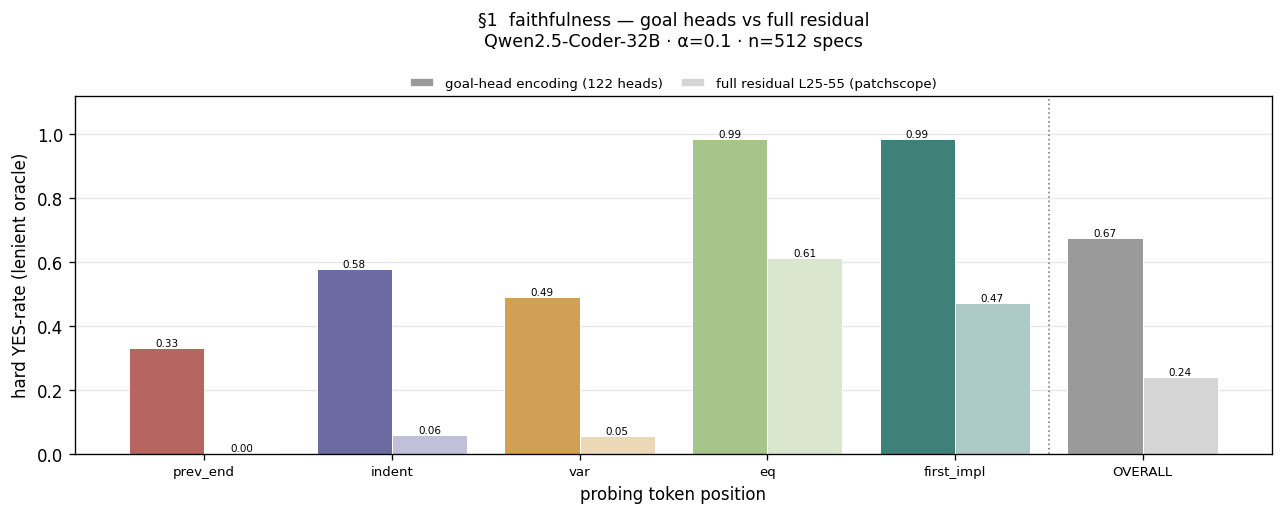

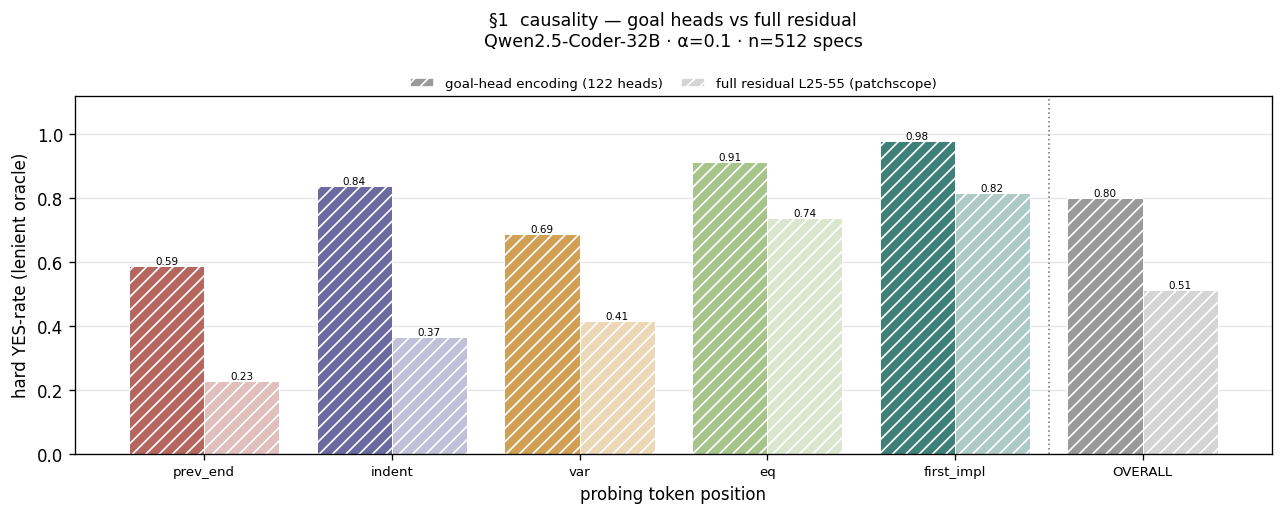

head - residual (overall hard_yes): faithfulness +0.435 | causality +0.288


In [4]:
base = {}
for mode in ["faithfulness", "causality"]:
    base[f"heads (122)  · {mode}"] = pick("Qwen2.5-Coder-32B-Instruct", mode, "additive_norm",
                                         alpha=0.1, n_specs=512, heads_name="goal")
    base[f"residual L25-55 · {mode}"] = pick("Qwen2.5-Coder-32B-Instruct", mode, "resid_norm",
                                             alpha=0.1, n_specs=512)
base_df = compare(base)
show(base_df, "§1  head encoding vs full residual — Qwen2.5-Coder-32B, additive/resid_norm α=0.1")

# one figure per metric; the two ENCODINGS sit side by side so they can be read against each other
for mode in ["faithfulness", "causality"]:
    series = {
        "goal-head encoding (122 heads)": _row(base_df, f"heads (122)  · {mode}"),
        "full residual L25-55 (patchscope)": _row(base_df, f"residual L25-55 · {mode}"),
    }
    fig, ax = plt.subplots(figsize=(1.55 * len(LAB) + 1.5, 4.4))
    paired_position_bars(ax, series, mode)
    ax.set_ylabel("hard YES-rate (lenient oracle)")
    ax.set_xlabel("probing token position")
    series_legend(ax, list(series), mode)
    ax.set_title(f"§1  {mode} — goal heads vs full residual\n"
                 f"Qwen2.5-Coder-32B · α=0.1 · n=512 specs", fontsize=10.5, pad=30)
    fig.tight_layout()
    fig.savefig(FIGDIR / f"01_baseline_{mode}.png", dpi=200, bbox_inches="tight")
    plt.show()

gap = {m: base_df.loc[f"heads (122)  · {m}", "overall"] - base_df.loc[f"residual L25-55 · {m}", "overall"]
       for m in ["faithfulness", "causality"]}
print("head - residual (overall hard_yes): " + " | ".join(f"{k} {v:+.3f}" for k, v in gap.items()))


## 2. Sparsity — read-out quality vs number of heads

Top-k head sets, all evaluated at `additive_norm` α=0.1 on the 256-spec corpus.

**Caveat, read before interpreting the curve:** the k=50…300 head sets were cut from masks trained at
*different* sparsity penalties (λ=100 for k≤100, λ=20 for 150–250, λ=5 for 300), because a λ=100 mask
simply does not contain 300 heads above threshold. So the x-axis mixes "how many heads" with "which
λ produced them" — a dip is not necessarily a head-count effect. The threshold-selected 122-head
`goal` set is plotted separately for reference (recomputed on the same 256 specs).

The sweep is also broken out **per token position** below. This is the more informative view: the
overall number averages five anchors whose absolute levels differ by ~0.6, so a change confined to
the early positions (`prev_end`, `indent`) — exactly where the interesting claim lives — is invisible
in the overall curve.



ref 122-head faithfulness: overall=0.676 (on 256 matched specs)
ref 122-head causality: overall=0.801 (on 256 matched specs)


 §2  overall hard_yes vs head count (α=0.1, 
                n_specs=256)                
                                            
        faithfulness   causality       lam  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  50           0.711       0.816   100.000  
  100          0.685       0.767   100.000  
  150          0.678       0.791    20.000  
  200          0.674       0.765    20.000  
  250          0.662       0.764    20.000  
  300          0.676       0.738     5.000

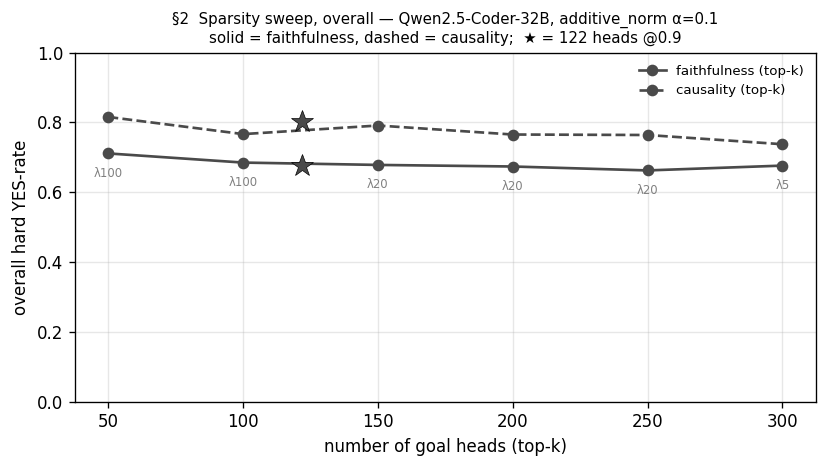

In [5]:
sparse = runs[(runs.model == "Qwen2.5-Coder-32B-Instruct") & (runs.strategy == "additive_norm")
              & (runs.heads_name.str.startswith("json:", na=False))].copy()
sparse["lam"] = sparse.heads_name.str.extract(r"lam(\d+)")[0].astype(int)
sparse = sparse.sort_values("n_heads")

rows = []
for _, r in sparse.iterrows():
    a = agg(r["dir"])
    rows.append(dict(mode=r["mode"], n_heads=int(r["n_heads"]), lam=int(r["lam"]), **a))
sp = pd.DataFrame(rows)

# reference point: the threshold-selected 122-head set, on the SAME 256 specs
ref_specs = spec_set(sparse.iloc[0]["dir"])
ref = {}
for mode in ["faithfulness", "causality"]:
    d = pick("Qwen2.5-Coder-32B-Instruct", mode, "additive_norm", alpha=0.1,
             n_specs=512, heads_name="goal")
    ref[mode] = agg(d, ref_specs)
    print(f"ref 122-head {mode}: overall={ref[mode]['overall']:.3f} "
          f"(on {ref[mode]['n_specs']} matched specs)")

piv = sp.pivot(index="n_heads", columns="mode", values="overall")
piv["lam"] = sp.groupby("n_heads").lam.first()
show(piv.rename_axis("n_heads"), "§2  overall hard_yes vs head count (α=0.1, n_specs=256)",
     cols=["faithfulness", "causality", "lam"], fmt="{:.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
for mode, ls in [("faithfulness", "-"), ("causality", "--")]:
    s = sp[sp["mode"] == mode].sort_values("n_heads")
    ax.plot(s.n_heads, s.overall, "o", ls=ls, color="#4a4a4a", label=f"{mode} (top-k)", lw=1.6)
    ax.plot([122], [ref[mode]["overall"]], "*", color="#4a4a4a", ms=14,
            markeredgecolor="black", markeredgewidth=0.4, zorder=5)
for _, r in sp[sp["mode"] == "faithfulness"].iterrows():
    ax.annotate(f"λ{r.lam}", (r.n_heads, r.overall), textcoords="offset points",
                xytext=(0, -14), ha="center", fontsize=7, color="grey")
ax.set_xlabel("number of goal heads (top-k)"); ax.set_ylabel("overall hard YES-rate")
ax.set_title("§2  Sparsity sweep, overall — Qwen2.5-Coder-32B, additive_norm α=0.1\n"
             "solid = faithfulness, dashed = causality;  ★ = 122 heads @0.9", fontsize=9)
ax.set_ylim(0, 1); ax.grid(alpha=.3); ax.set_axisbelow(True)
ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(FIGDIR / "02_sparsity_sweep.png", dpi=200, bbox_inches="tight"); plt.show()


   §2b  hard_yes by token position vs head count — faithfulness   
                       (α=0.1, n_specs=256)                       
                                                                  
        prev_end   indent     var      eq   first_impl   overall  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  50       0.271    0.660   0.647   0.989        0.988     0.711  
  100      0.296    0.614   0.558   0.967        0.991     0.685  
  150      0.326    0.574   0.531   0.983        0.976     0.678  
  200      0.319    0.554   0.531   0.973        0.991     0.674  
  250      0.266    0.575   0.494   0.986        0.991     0.662  
  300      0.271    0.588   0.551   0.985        0.986     0.676

§2b  hard_yes by token position vs head count — causality (α=0.1, 
                           n_specs=256)                           
                                                                  
        prev_end   indent     var      eq   first_impl   overall  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  50       0.603    0.855   0.745   0.915        0.960     0.816  
  100      0.561    0.765   0.616   0.911        0.980     0.767  
  150      0.564    0.828   0.680   0.915        0.969     0.791  
  200      0.541    0.775   0.648   0.901        0.961     0.765  
  250      0.507    0.742   0.678   0.917        0.975     0.764  
  300      0.476    0.711   0.637   0.894        0.969     0.738

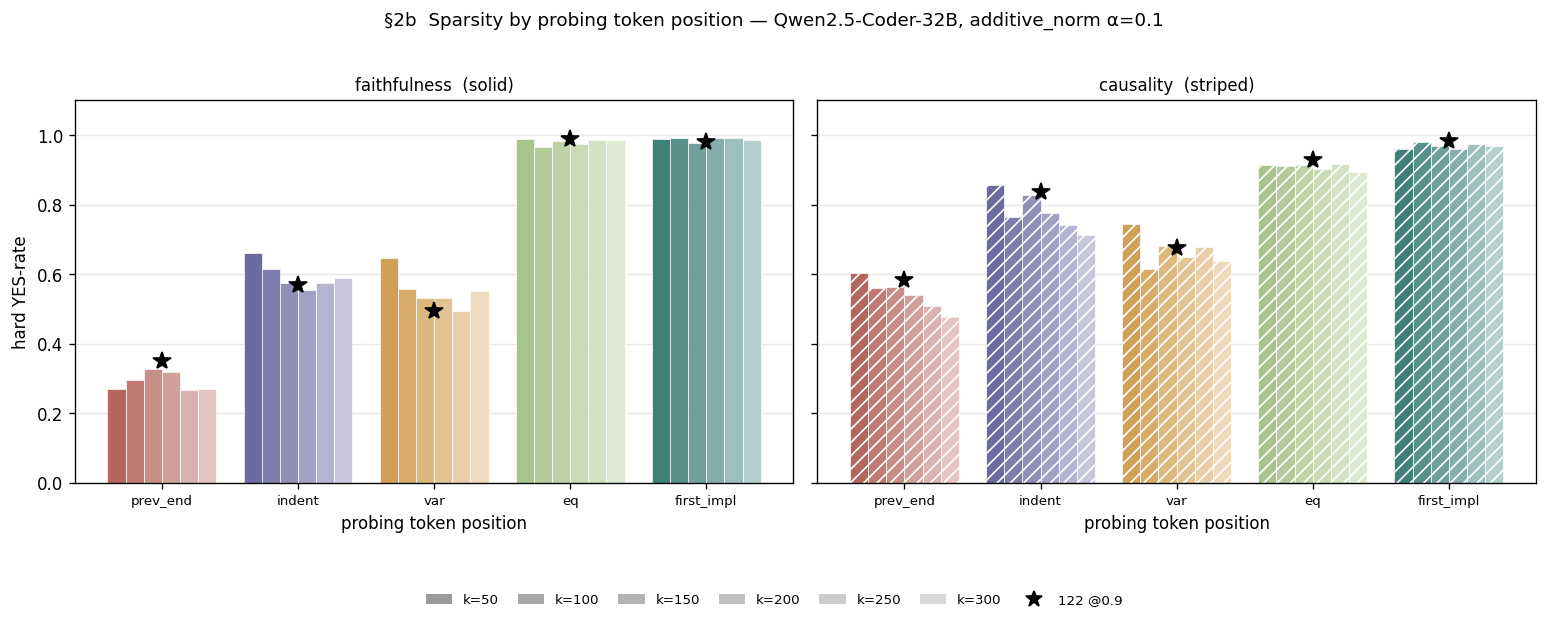

   §2b  sensitivity to head count, per position (span over    
                          k=50..300)                          
                                                              
  mode           position       min     max    span   best k  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  faithfulness   prev_end     0.266   0.326   0.060      150  
  faithfulness   indent       0.554   0.660   0.106       50  
  faithfulness   var          0.494   0.647   0.154       50  
  faithfulness   eq           0.967   0.989   0.023       50  
  faithfulness   first_impl   0.976   0.991   0.015      100  
  faithfulness   overall      0.662   0.711   0.049       50  
  causality      prev_end     0.476   0.603   0.127       50  
  causality      indent       0.711   0.855   0.144       50  
  causality      var          0.616   0.745   0.129       50  
  causality      eq           0.894   0.917   0.024      250  
  causality      first_impl   0.960   0.980   0.021      100  
  causality      overall      0.738   0.816   0.078       50

In [6]:
# ── §2b sparsity, per token position ─────────────────────────────────────────
# Same runs as above; `sp` already carries one column per anchor (from agg()).

for mode in ["faithfulness", "causality"]:
    s = sp[sp["mode"] == mode].sort_values("n_heads").set_index("n_heads")
    tbl = s[ANCHORS].copy()
    tbl["overall"] = s["overall"]
    show(tbl, f"§2b  hard_yes by token position vs head count — {mode} (α=0.1, n_specs=256)",
         cols=ANCHORS + ["overall"])

ks = sorted(sp.n_heads.unique())
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, (mode, hatch) in zip(axes, [("faithfulness", None), ("causality", HATCH)]):
    s = sp[sp["mode"] == mode].set_index("n_heads")
    x, w = np.arange(len(ANCHORS)), 0.8 / len(ks)
    for j, k in enumerate(ks):
        off = (j - (len(ks) - 1) / 2) * w
        ax.bar(x + off, [s.loc[k, a] for a in ANCHORS], w,
               color=[shade(ANCHOR_COLOR[a], 0.62 * j / (len(ks) - 1)) for a in ANCHORS],
               edgecolor="white", linewidth=0.4, hatch=hatch)
    # the threshold-selected 122-head set, same 256 specs
    ax.plot(x, [ref[mode][a] for a in ANCHORS], "*", color="black", ms=11, zorder=6,
            label="122 heads @0.9")
    ax.set_xticks(x); ax.set_xticklabels(ANCHORS, fontsize=8)
    ax.set_xlabel("probing token position")
    ax.set_title(f"{mode}  ({'solid' if hatch is None else 'striped'})", fontsize=10, pad=6)
    ax.set_ylim(0, 1.10); ax.grid(axis="y", alpha=.3); ax.set_axisbelow(True)
axes[0].set_ylabel("hard YES-rate")
# k ramp, drawn in neutral grey so it does not compete with the position colors
fig.legend(handles=[Patch(facecolor=shade(NEUTRAL, 0.62 * j / (len(ks) - 1)), label=f"k={k}")
                    for j, k in enumerate(ks)] + [plt.Line2D([], [], marker="*", color="black",
                                                             ls="", ms=10, label="122 @0.9")],
           loc="lower center", bbox_to_anchor=(0.5, -0.13), ncol=len(ks) + 1, fontsize=8,
           frameon=False, columnspacing=1.4)
fig.suptitle("§2b  Sparsity by probing token position — Qwen2.5-Coder-32B, additive_norm α=0.1",
             y=1.02, fontsize=11)
plt.tight_layout()
plt.savefig(FIGDIR / "02b_sparsity_by_anchor.png", dpi=200, bbox_inches="tight")
plt.show()

# how much does each position move across the whole sweep?
rng = []
for mode in ["faithfulness", "causality"]:
    s = sp[sp["mode"] == mode]
    for a in ANCHORS + ["overall"]:
        rng.append(dict(mode=mode, position=a, min=s[a].min(), max=s[a].max(),
                        span=s[a].max() - s[a].min(),
                        best_k=int(s.loc[s[a].idxmax(), "n_heads"])))
rng = pd.DataFrame(rng)
t = Table(title="§2b  sensitivity to head count, per position (span over k=50..300)",
          box=SIMPLE_HEAVY)
for c in ["mode", "position", "min", "max", "span", "best k"]:
    t.add_column(c, justify="left" if c in ("mode", "position") else "right")
for _, r in rng.iterrows():
    t.add_row(r["mode"], r.position, f"{r['min']:.3f}", f"{r['max']:.3f}", f"{r.span:.3f}",
              str(r.best_k), style="bold" if r.span > 0.10 else None)
rich_print(t)


## 3. Comparison axes

All three axes use `replace` α=1.0, the one strategy every model in them has been run at. Numbers are
recomputed on the **matched corpus** within each axis (the 14B runs cover 256 specs, the 32B runs 512).

- **3a size** — Qwen2.5-Coder 14B vs 32B. Also shown at `additive_norm` α=0.1, available for both.
- **3b code** — Qwen2.5-32B-Instruct vs Qwen2.5-Coder-32B-Instruct (same base, +5.5T code tokens).
- **3c RL** — Olmo-3.1-32B-Instruct-SFT vs -Instruct (the RLVR stage is the only difference).

**Confounds carried into every panel:** the two members of an axis do not have the same number of
goal heads (see the `n_heads` column), so a difference mixes *representation quality* with
*intervention size*. On 3c the SFT mask was additionally trained on ~30% fewer mined pivots
(851 vs 1222), which depresses head count on its own. Treat these as descriptive until an equal-N
arm exists.


In [7]:
AXES = {
    "3a  size  (replace α=1.0)": {
        "Coder-14B  (88 heads)": ("Qwen2.5-Coder-14B-Instruct", "replace", 1.0, None),
        "Coder-32B  (122 heads)": ("Qwen2.5-Coder-32B-Instruct", "replace", 1.0, 512),
    },
    "3a  size  (additive_norm α=0.1)": {
        "Coder-14B  (88 heads)": ("Qwen2.5-Coder-14B-Instruct", "additive_norm", 0.1, None),
        "Coder-32B  (122 heads)": ("Qwen2.5-Coder-32B-Instruct", "additive_norm", 0.1, 512),
    },
    "3b  code-finetuning  (replace α=1.0)": {
        "Qwen2.5-32B-Instruct  (108)": ("Qwen2.5-32B-Instruct", "replace", 1.0, 512),
        "Qwen2.5-Coder-32B     (122)": ("Qwen2.5-Coder-32B-Instruct", "replace", 1.0, 512),
    },
    "3c  RL-finetuning  (replace α=1.0)": {
        "Olmo-3.1-32B SFT   (79)": ("Olmo-3.1-32B-Instruct-SFT", "replace", 1.0, 512),
        "Olmo-3.1-32B +RL   (130)": ("Olmo-3.1-32B-Instruct", "replace", 1.0, 512),
    },
}

# An axis needs BOTH members in BOTH modes; a partner that was never run should skip that axis,
# not abort §3 and take the complete axes down with it.
axis_tables, AXIS_MISSING = {}, {}
for axis_name, members in AXES.items():
    for mode in ["faithfulness", "causality"]:
        labelled, missing = {}, []
        for lbl, (m, strat, a, ns) in members.items():
            try:
                labelled[lbl] = pick(m, mode, strat, alpha=a, n_specs=ns, heads_name="goal")
            except AssertionError:
                missing.append(f"{m} [{mode}]")
        if missing:
            AXIS_MISSING.setdefault(axis_name, []).extend(missing)
            continue
        df = compare(labelled)
        axis_tables[(axis_name, mode)] = df
        show(df, f"§{axis_name}  ·  {mode}")

if AXIS_MISSING:
    for axis_name, miss in AXIS_MISSING.items():
        rich_print(f"[red]skipped §{axis_name}[/red] — no run for: "
                   + ", ".join(sorted(set(miss))))


matched corpus: 256 specs


                     §3a  size  (replace α=1.0)  ·  faithfulness                     
                                                                                     
                           overall   prev_end   indent     var      eq   first_impl  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  Coder-14B  (88 heads)      0.620      0.243    0.583   0.395   0.963        0.918  
  Coder-32B  (122 heads)     0.662      0.269    0.608   0.519   0.970        0.945

matched corpus: 256 specs


                      §3a  size  (replace α=1.0)  ·  causality                       
                                                                                     
                           overall   prev_end   indent     var      eq   first_impl  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  Coder-14B  (88 heads)      0.586      0.270    0.509   0.532   0.845        0.774  
  Coder-32B  (122 heads)     0.808      0.538    0.795   0.764   0.961        0.984

matched corpus: 256 specs


                  §3a  size  (additive_norm α=0.1)  ·  faithfulness                  
                                                                                     
                           overall   prev_end   indent     var      eq   first_impl  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  Coder-14B  (88 heads)      0.677      0.336    0.640   0.530   0.960        0.918  
  Coder-32B  (122 heads)     0.676      0.350    0.567   0.495   0.988        0.981

... (6 outputs left out)

matched corpus: 512 specs


                 §3c  RL-finetuning  (replace α=1.0)  ·  faithfulness                  
                                                                                       
                             overall   prev_end   indent     var      eq   first_impl  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  Olmo-3.1-32B SFT   (79)      0.616      0.185    0.676   0.595   0.889        0.736  
  Olmo-3.1-32B +RL   (130)     0.410      0.040    0.304   0.135   0.779        0.792

matched corpus: 512 specs


                   §3c  RL-finetuning  (replace α=1.0)  ·  causality                   
                                                                                       
                             overall   prev_end   indent     var      eq   first_impl  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  Olmo-3.1-32B SFT   (79)      0.508      0.136    0.452   0.253   0.851        0.848  
  Olmo-3.1-32B +RL   (130)     0.715      0.331    0.802   0.547   0.943        0.954

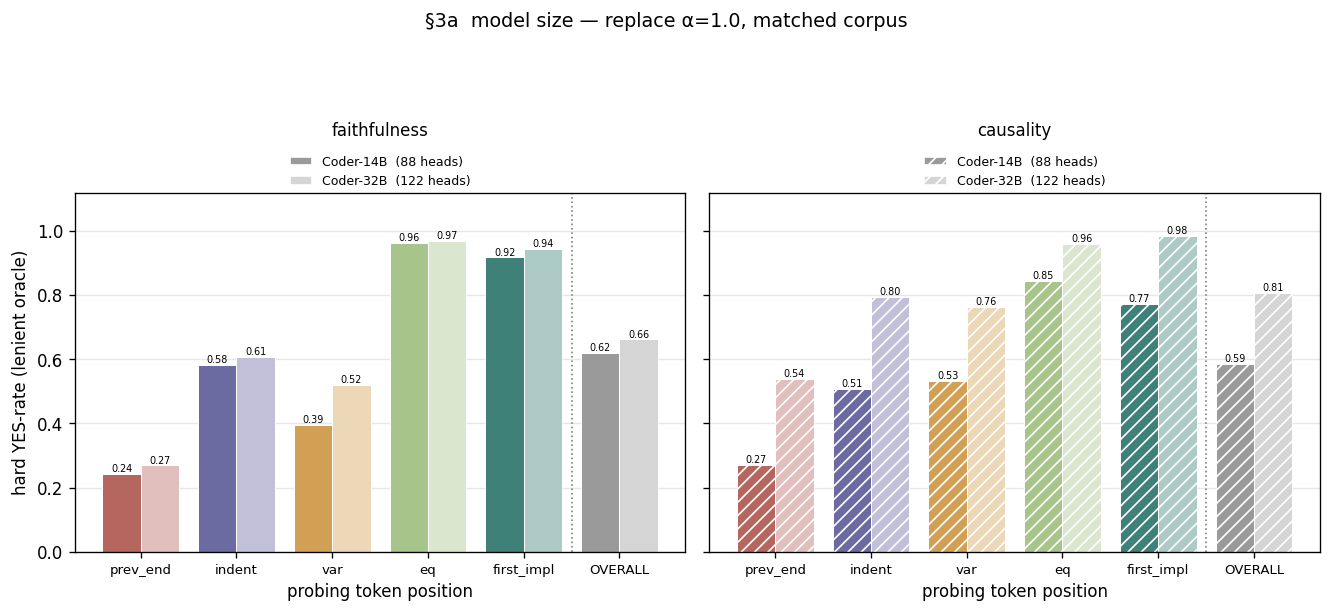

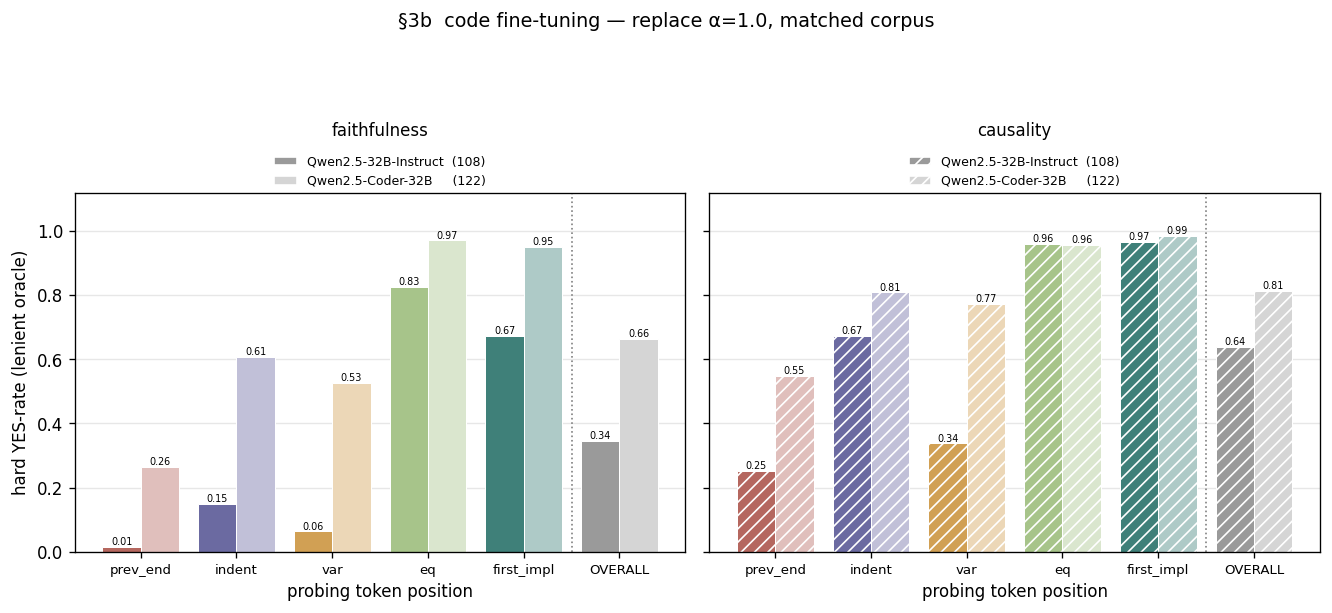

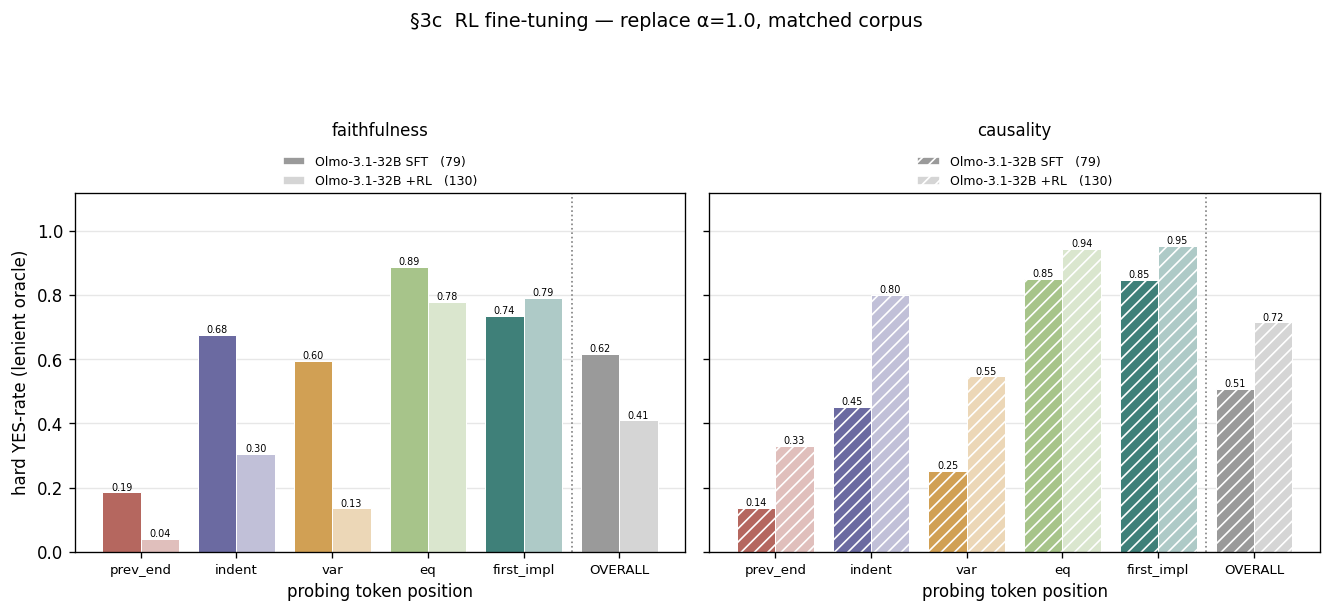

In [8]:
# ── one figure per comparison AXIS; faithfulness | causality side by side ──
# Grouped by axis rather than by metric: the question each panel answers is "does this axis move
# the read-out?", and that is only legible when both metrics for the SAME pair of models sit
# together. Metric is still encoded by fill (solid = faithfulness, striped = causality), so the
# two panels stay visually distinguishable, and `sharey` keeps them on one scale.
panels = [k for k in AXES if "additive_norm" not in k
          and all((k, m) in axis_tables for m in ("faithfulness", "causality"))]
MODES = ["faithfulness", "causality"]
AXIS_TITLE = {"3a": "model size", "3b": "code fine-tuning", "3c": "RL fine-tuning"}

if not panels:
    rich_print("[red]no axis has both metrics on disk — nothing to plot[/red]")
for axis_name in panels:
    tag = axis_name.split()[0]
    fig, axs = plt.subplots(1, len(MODES), figsize=(5.6 * len(MODES), 4.6), sharey=True)
    axs = np.atleast_1d(axs)
    for ax, mode in zip(axs, MODES):
        df = axis_tables[(axis_name, mode)]
        series = {lbl.strip(): _row(df, lbl) for lbl in df.index}
        paired_position_bars(ax, series, mode, fs=5.8)
        ax.set_xlabel("probing token position")
        series_legend(ax, list(series), mode, ncol=1, fontsize=7.5)
        ax.set_title(mode, fontsize=10, pad=34)
    axs[0].set_ylabel("hard YES-rate (lenient oracle)")
    fig.suptitle(f"§{tag}  {AXIS_TITLE.get(tag, tag)} — replace \u03b1=1.0, matched corpus",
                 y=1.10, fontsize=11.5)
    fig.tight_layout()
    fig.savefig(FIGDIR / f"03_axis_{tag}_{AXIS_TITLE.get(tag, tag).replace(' ', '_')}.png",
                dpi=200, bbox_inches="tight")
    plt.show()

## 4. Anchor profile — is the goal readable *before* the sub-task starts?

Anchors are ordered by position on the assignment line:

```
    a = n % 2 == 0
^^^^ ^ ^ ^
|    | | └─ first_impl  the sub-task's FIRST emitted token
|    | └─── eq          the "="
|    └───── var         the variable letter (a/b/c)
└────────── indent      the line's leading whitespace   <- before any sub-task token
   prev_end             the newline ending the previous line
```

`prev_end` and `indent` both precede the sub-task entirely. If `hard_yes` is already high there, the
goal is *encoded before it is written* — which is the claim for the Qwen-Coder family. The
**earliness ratio** `hard_yes[indent] / hard_yes[first_impl]` makes that comparable across models:
≈1 means the goal is fully formed at the indent, ≪1 means it only materialises once emission starts.


                  §4  goal availability before emission (replace α=1.0, matched per axis)                   
                                                                                                            
  axis   model                         mode           indent   first_impl   earliness  (indent/first_impl)  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  3a     Coder-14B  (88 heads)         causality       0.509        0.774                             0.66  
  3a     Coder-32B  (122 heads)        causality       0.795        0.984                             0.81  
  3b     Qwen2.5-32B-Instruct  (108)   causality       0.672        0.967                             0.70  
  3b     Qwen2.5-Coder-32B     (122)   causality       0.809        0.986                             0.82  
  3c     Olmo-3.1-32B SFT   (79)       causality       0.452        0.848                             0.53  
  3c     Olmo-3.1-32B +RL   (130)      causality       0.802        0.954                             0.84  
  3a     Coder-14B  (88 heads)         faithfulness    0.583        0.918                             0.63  
  3a     Coder-32B  (122 heads)        faithfulness    0.608        0.945                             0.64  
  3b     Qwen2.5-32B-Instruct  (108)   faithfulness    0.148        0.674                             0.22  
  3b     Qwen2.5-Coder-32B     (122)   faithfulness    0.608        0.950                             0.64  
  3c     Olmo-3.1-32B SFT   (79)       faithfulness    0.676        0.736                             0.92  
  3c     Olmo-3.1-32B +RL   (130)      faithfulness    0.304        0.792                             0.38

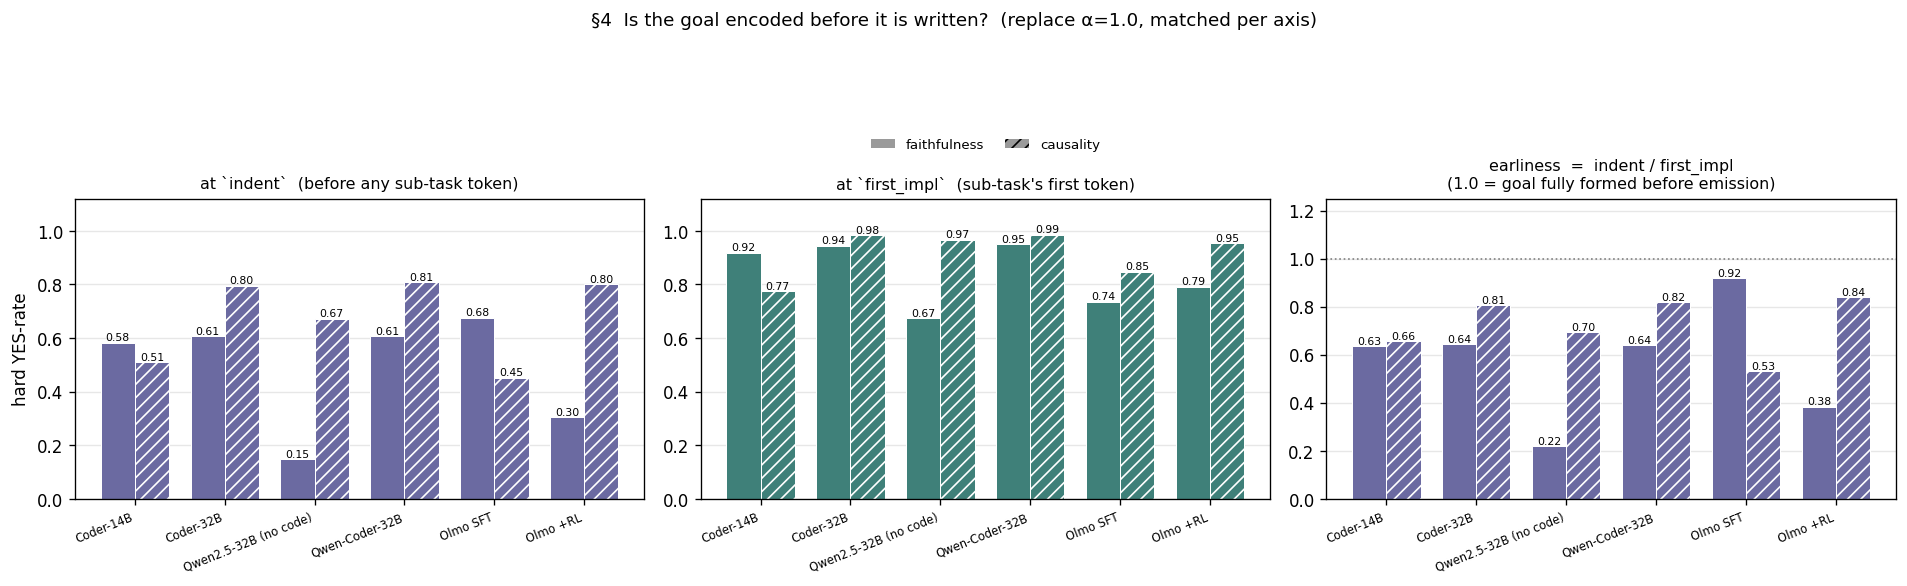

In [9]:
def anchor_profile(members, mode, strategy="replace", alpha=1.0):
    labelled = {lbl: pick(m, mode, strategy, alpha=alpha, n_specs=ns, heads_name="goal")
                for lbl, (m, strategy_, alpha_, ns) in members.items()
                for strategy, alpha in [(strategy_, alpha_)]}
    return compare(labelled)


prof_rows = []
for axis_name, members in AXES.items():
    if "additive_norm" in axis_name:
        continue
    for mode in ["faithfulness", "causality"]:
        df = axis_tables[(axis_name, mode)]
        for lbl, r in df.iterrows():
            prof_rows.append(dict(
                axis=axis_name.split()[0], model=lbl.strip(), mode=mode,
                pre_subtask=float(np.nanmean([r["prev_end"], r["indent"]])),
                indent=r["indent"], first_impl=r["first_impl"], overall=r["overall"],
                earliness=r["indent"] / r["first_impl"] if r["first_impl"] else np.nan))
prof = pd.DataFrame(prof_rows).drop_duplicates(subset=["model", "mode"])

t = Table(title="§4  goal availability before emission (replace α=1.0, matched per axis)",
          box=SIMPLE_HEAVY)
for c in ["axis", "model", "mode", "indent", "first_impl", "earliness  (indent/first_impl)"]:
    t.add_column(c, justify="left" if c in ("axis", "model", "mode") else "right")
for _, r in prof.sort_values(["mode", "axis"]).iterrows():
    style = "bold" if r.earliness >= 0.95 else None
    t.add_row(r.axis, r.model, r["mode"], f"{r.indent:.3f}", f"{r.first_impl:.3f}",
              f"{r.earliness:.2f}", style=style)
rich_print(t)

# ── figure: how early is the goal available? (§3 already has the full per-position bars) ──
SHORT = {"Coder-14B  (88 heads)": "Coder-14B", "Coder-32B  (122 heads)": "Coder-32B",
         "Qwen2.5-32B-Instruct  (108)": "Qwen2.5-32B (no code)",
         "Qwen2.5-Coder-32B     (122)": "Qwen-Coder-32B",
         "Olmo-3.1-32B SFT   (79)": "Olmo SFT", "Olmo-3.1-32B +RL   (130)": "Olmo +RL"}
MODEL_ROWS = {}
for axis_name, members in AXES.items():
    if "additive_norm" in axis_name:
        continue
    for mode in ["faithfulness", "causality"]:
        for lbl, r in axis_tables[(axis_name, mode)].iterrows():
            MODEL_ROWS.setdefault(lbl, {})[mode] = r
mdls = list(MODEL_ROWS)
xt = [SHORT.get(m, m) for m in mdls]

# colour by the POSITION each panel is about (indent), hatch by mode, as elsewhere
C_IND, C_FST = ANCHOR_COLOR["indent"], ANCHOR_COLOR["first_impl"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
x, w = np.arange(len(mdls)), 0.38
for ax, (key, col, title) in zip(axes, [
        ("indent", C_IND, "at `indent`  (before any sub-task token)"),
        ("first_impl", C_FST, "at `first_impl`  (sub-task's first token)")]):
    for k, (mode, hatch) in enumerate([("faithfulness", None), ("causality", HATCH)]):
        vals = [MODEL_ROWS[m][mode][key] for m in mdls]
        bars = ax.bar(x + (k - 0.5) * w, vals, w, color=col, edgecolor="white", linewidth=0.6,
                      hatch=hatch)
        for r in bars:
            ax.annotate(f"{r.get_height():.2f}", (r.get_x() + r.get_width() / 2, r.get_height()),
                        ha="center", va="bottom", fontsize=6.5)
    ax.set_title(title, fontsize=9.5, pad=6)
    ax.set_xticks(x); ax.set_xticklabels(xt, fontsize=7, rotation=22, ha="right")
    ax.set_ylim(0, 1.12); ax.grid(axis="y", alpha=.3); ax.set_axisbelow(True)
axes[0].set_ylabel("hard YES-rate")

ax = axes[2]
for k, (mode, hatch) in enumerate([("faithfulness", None), ("causality", HATCH)]):
    vals = [MODEL_ROWS[m][mode]["indent"] / MODEL_ROWS[m][mode]["first_impl"] for m in mdls]
    bars = ax.bar(x + (k - 0.5) * w, vals, w, color=C_IND, edgecolor="white", linewidth=0.6,
                  hatch=hatch)
    for r in bars:
        ax.annotate(f"{r.get_height():.2f}", (r.get_x() + r.get_width() / 2, r.get_height()),
                    ha="center", va="bottom", fontsize=6.5)
ax.axhline(1.0, color="grey", ls=":", lw=1)
ax.set_title("earliness  =  indent / first_impl\n(1.0 = goal fully formed before emission)",
             fontsize=9.5, pad=6)
ax.set_xticks(x); ax.set_xticklabels(xt, fontsize=7, rotation=22, ha="right")
ax.set_ylim(0, 1.25); ax.grid(axis="y", alpha=.3); ax.set_axisbelow(True)
metric_legend(axes[1], bbox_to_anchor=(0.5, 1.14))
fig.suptitle("§4  Is the goal encoded before it is written?  (replace α=1.0, matched per axis)",
             y=1.10, fontsize=11)
plt.tight_layout()
plt.savefig(FIGDIR / "04_anchor_profile.png", dpi=200, bbox_inches="tight")
plt.show()


## 5. What is on disk, and what is missing

The cell below is the full inventory. Known gaps for these analyses:

- **3b / 3c exist only at `replace` α=1.0.** There is no `additive_norm` run for
  `Qwen2.5-32B-Instruct`, `Olmo-3.1-32B-Instruct` or `-SFT`. If `additive_norm` turns out to be the
  better operating point (it is, for 14B faithfulness), those three models need 6 more runs before
  the axes can be reported at the best strategy.
- **No equal-N arm anywhere.** Every axis compares different head counts (88/122, 108/122, 79/130).
  A top-k control at k = min(pair) would separate representation quality from intervention size —
  `--heads <path>.json` already supports it, and §2's `head_sets/.../goal_topk/` files show the
  pattern.
- **The 14B goal heads were selected unbanded** (`goal_band=(0,48)`) while 32B used `(25,56)`. That
  asymmetry sits inside axis 3a.
- **Sparsity λ provenance is mixed** (§2 caveat).


In [10]:
inv = runs[["model", "mode", "strategy", "alpha", "heads_name", "n_heads", "goal_band",
            "n_specs", "n_records", "summary_hard_yes"]].sort_values(
    ["model", "mode", "strategy", "n_heads"])
pd.set_option("display.width", 200, "display.max_rows", 100, "display.max_colwidth", 40)
print(inv.to_string(index=False))


                     model         mode      strategy  alpha               heads_name  n_heads goal_band  n_specs  n_records  summary_hard_yes
     Olmo-3.1-32B-Instruct    causality       replace    1.0                     goal    130.0  (10, 36)      512      10235          0.715388
     Olmo-3.1-32B-Instruct faithfulness       replace    1.0                     goal    130.0  (10, 36)      512      10235          0.409770
 Olmo-3.1-32B-Instruct-SFT    causality       replace    1.0                     goal     79.0  (10, 36)      512      10235          0.507963
 Olmo-3.1-32B-Instruct-SFT faithfulness       replace    1.0                     goal     79.0  (10, 36)      512      10235          0.616023
      Qwen2.5-32B-Instruct    causality       replace    1.0                     goal    108.0  (25, 56)      512      10235          0.638007
      Qwen2.5-32B-Instruct faithfulness       replace    1.0                     goal    108.0  (25, 56)      512      10235          0.344993